In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

In [3]:
# Load dataset wastewater_model_Cleaned data.csv
print("Loading cleaned dataset...")
# Make sure file path matches your workspace directory
df = pd.read_csv(r'C:\Users\VICTUS\Documents\BACHELOR OF COMPUTER SCIENCE\FYP\Effluent Water Quality Monitoring System\Water Quality Monitoring\wastewater_model_Cleaned data.csv')

# Parse dates and sort chronologically[cite: 1, 4]
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)
df = df.drop_duplicates(subset=['date']).reset_index(drop=True)

# Exclude the date column
feature_cols = [c for c in df.columns if c != 'date']

# Interpolate missing values and clip extreme measurement noise[cite: 1, 4]
df[feature_cols] = df[feature_cols].interpolate(method='linear', limit_direction='both')
for col in feature_cols:
    lb = df[col].quantile(0.001)
    ub = df[col].quantile(0.999)
    df[col] = df[col].clip(lower=lb, upper=ub)

print(f"Total Cleaned Dataset Rows: {len(df)}")

# Split the dataset into train and test
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy().reset_index(drop=True)

print(f"Training Set Size (80%): {len(train_df)} rows")
print(f"Testing Set Size (20%):  {len(test_df)} rows")

Loading cleaned dataset...
Total Cleaned Dataset Rows: 525600
Training Set Size (80%): 420480 rows
Testing Set Size (20%):  105120 rows


In [4]:
# Feature scaling min max scaler part
iso_scaler = MinMaxScaler()

# Fit strictly on training data to prevent data leakage[cite: 1, 4]
X_train_scaled = iso_scaler.fit_transform(train_df[feature_cols])
X_test_scaled = iso_scaler.transform(test_df[feature_cols])


print("\nTraining Isolation Forest model...")
# Contamination rate set to 2% (~0.02) based on operational risk thresholds
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train_scaled)
print("✓ Isolation Forest training completed successfully!")

# predict anomaly on test set
test_preds = iso_forest.predict(X_test_scaled)
y_pred_binary = np.where(test_preds == -1, 1, 0)

# Decision scores (lower score = more anomalous)
anomaly_scores = iso_forest.decision_function(X_test_scaled)

# Append predictions and anomaly decision scores back to test dataframe
test_df['anomaly_pred'] = y_pred_binary
test_df['anomaly_score'] = anomaly_scores

detected_anomalies = test_df[test_df['anomaly_pred'] == 1]
print(f"Detected Anomalies in Testing Set: {len(detected_anomalies)} / {len(test_df)} ({len(detected_anomalies)/len(test_df)*100:.2f}%)")


Training Isolation Forest model...
✓ Isolation Forest training completed successfully!
Detected Anomalies in Testing Set: 1587 / 105120 (1.51%)


In [5]:
# -------------------------------------------------------------------------
# Step 6: Ground Truth Evaluation Proxy (Critical Limits)[cite: 3]
# -------------------------------------------------------------------------
# Operational threshold violation proxy: T1_O2 < 0.5 mg/L or T1_NH4 > 5.0 mg/L
y_true_binary = np.where((test_df['T1_O2'] < 0.5) | (test_df['T1_NH4'] > 5.0), 1, 0)

precision, recall, f1, _ = precision_recall_fscore_support(y_true_binary, y_pred_binary, average='binary')

print("\n--- Isolation Forest Anomaly Detection Evaluation ---")
print(classification_report(y_true_binary, y_pred_binary, target_names=['Normal (0)', 'Anomaly (1)']))


import joblib
from sklearn.ensemble import IsolationForest

# 1. Initialize and fit the Isolation Forest model on scaled training features
iso_forest = IsolationForest(
    n_estimators=100, contamination=0.02, random_state=42
)
iso_forest.fit(X_train_scaled)  # <-- MUST CALL .fit() BEFORE SAVING

# 2. Re-save the fitted model and scaler
joblib.dump(iso_forest, "isolation_forest_model.pkl")
joblib.dump(iso_scaler, "iso_scaler.pkl")

print("✓ Fitted Isolation Forest model saved successfully!")

# -------------------------------------------------------------------------
# Step 7: Save Model & Scaler for Streamlit Integration
# -------------------------------------------------------------------------
import joblib
joblib.dump(iso_forest, 'isolation_forest_model.pkl')
joblib.dump(iso_scaler, 'iso_scaler.pkl')
print("✓ Saved 'isolation_forest_model.pkl' and 'iso_scaler.pkl' for Streamlit!")


--- Isolation Forest Anomaly Detection Evaluation ---
              precision    recall  f1-score   support

  Normal (0)       0.42      0.98      0.59     44040
 Anomaly (1)       0.55      0.01      0.03     61080

    accuracy                           0.42    105120
   macro avg       0.48      0.50      0.31    105120
weighted avg       0.49      0.42      0.26    105120

✓ Fitted Isolation Forest model saved successfully!
✓ Saved 'isolation_forest_model.pkl' and 'iso_scaler.pkl' for Streamlit!


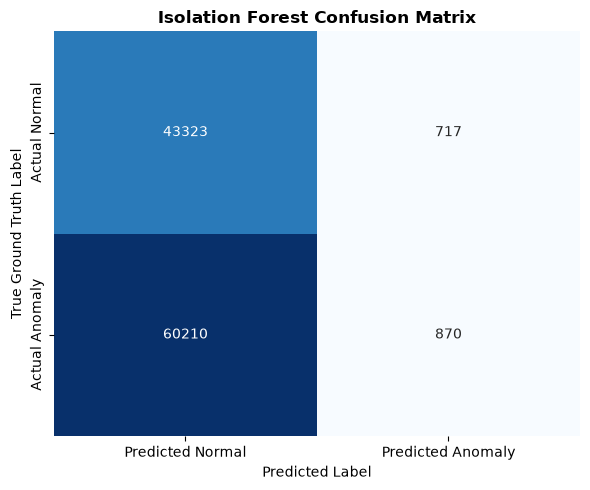

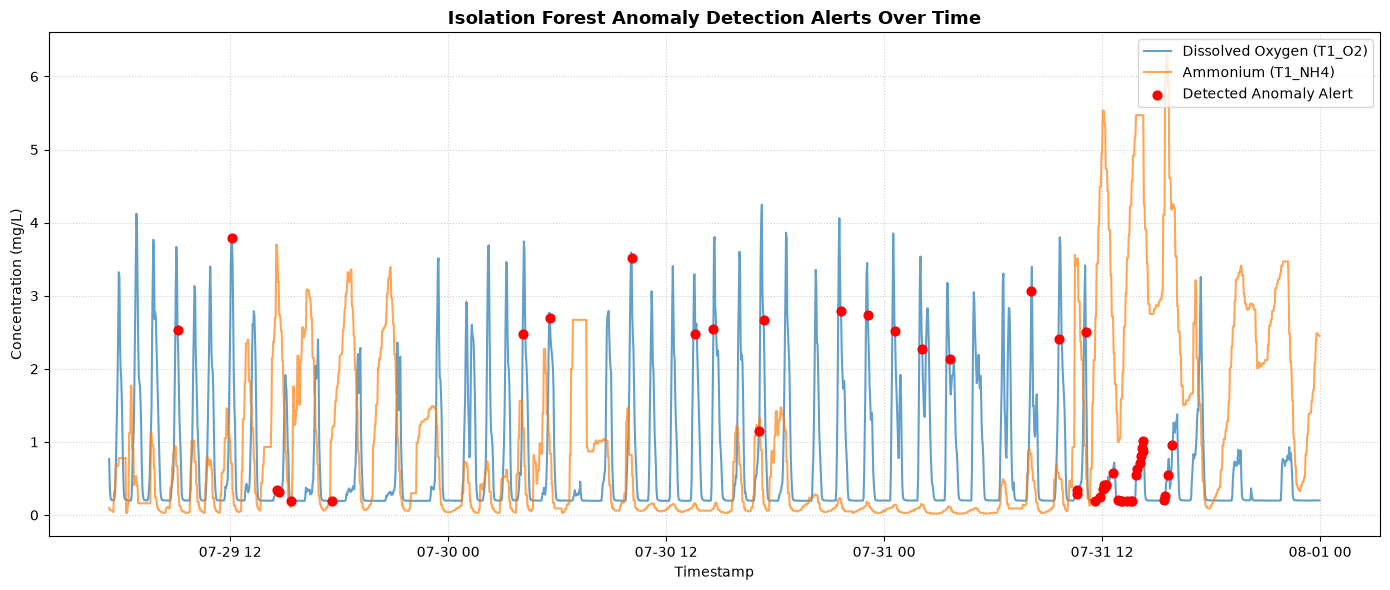

In [6]:
# -------------------------------------------------------------------------
# Step 8: Visualizations (Confusion Matrix & Time-Series Alerts)
# -------------------------------------------------------------------------
# Chart 1: Confusion Matrix
cm = confusion_matrix(y_true_binary, y_pred_binary)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['Actual Normal', 'Actual Anomaly'])
plt.title('Isolation Forest Confusion Matrix', fontsize=12, fontweight='bold')
plt.ylabel('True Ground Truth Label', fontsize=10)
plt.xlabel('Predicted Label', fontsize=10)
plt.tight_layout()
plt.show()

# Chart 2: Anomaly Over Time Scatter Plot
subset_display = 2000
sample_test = test_df.iloc[-subset_display:].copy()

plt.figure(figsize=(14, 6))
plt.plot(sample_test['date'], sample_test['T1_O2'], label='Dissolved Oxygen (T1_O2)', color='#1f77b4', alpha=0.7)
plt.plot(sample_test['date'], sample_test['T1_NH4'], label='Ammonium (T1_NH4)', color='#ff7f0e', alpha=0.7)

anomalies_sample = sample_test[sample_test['anomaly_pred'] == 1]
plt.scatter(anomalies_sample['date'], anomalies_sample['T1_O2'], color='red', label='Detected Anomaly Alert', s=40, zorder=5)

plt.title('Isolation Forest Anomaly Detection Alerts Over Time', fontsize=13, fontweight='bold')
plt.xlabel('Timestamp', fontsize=10)
plt.ylabel('Concentration (mg/L)', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()